# Exploring EuroSAT RGB

Each folder is a land-cover class. 

In [ ]:
from pathlib import Path
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

root = Path.cwd()

if root.name == "analysis":
    root = root.parent

image_dir = root / "Dataset" / "EuroSAT_RGB"
paths = sorted(image_dir.glob("*/*.jpg"))

if not paths:
    raise FileNotFoundError("Open this notebook from the project or analysis folder.")

## Check the files

- open each JPEG and record its size and color mode. 

In [ ]:
rows = []
issues = []
thumbnails = []

for path in paths:
    try:
        with Image.open(path) as img:
            img.load()

            if img.mode != "RGB" or img.size != (64, 64):
                issues.append((path.name, f"{img.mode}, {img.size}"))
                continue

            rgb = np.asarray(img)
            gray = img.convert("L")
            thumb = gray.resize((16, 16), Image.Resampling.BOX)
            hash_grid = np.asarray(gray.resize((9, 8), Image.Resampling.BOX))

    except OSError as error:
        issues.append((path.name, str(error)))
        continue

    brightness = rgb.mean(axis=(0, 1)) @ [0.299, 0.587, 0.114]

    # The small hash records where neighboring pixels get brighter.
    pattern = np.packbits(hash_grid[:, 1:] > hash_grid[:, :-1]).tobytes().hex()

    rows.append({
        "path": path, "class": path.parent.name, "brightness": brightness,
        "contrast": np.asarray(gray).std(), "pattern": pattern,
        "pixel_hash": hashlib.sha256(rgb.tobytes()).hexdigest(),
    })

    thumbnails.append(np.asarray(thumb).ravel())

tiles = pd.DataFrame(rows)
thumbnails = np.asarray(thumbnails)

print(f"{len(tiles):,} usable RGB tiles out of {len(paths):,} files")
print("Files to review:", len(issues), issues[:5])
print("Repeated pixel arrays:", tiles["pixel_hash"].duplicated().sum())

27,000 usable RGB tiles out of 27,000 files
Files to review: 0 []
Repeated pixel arrays: 0


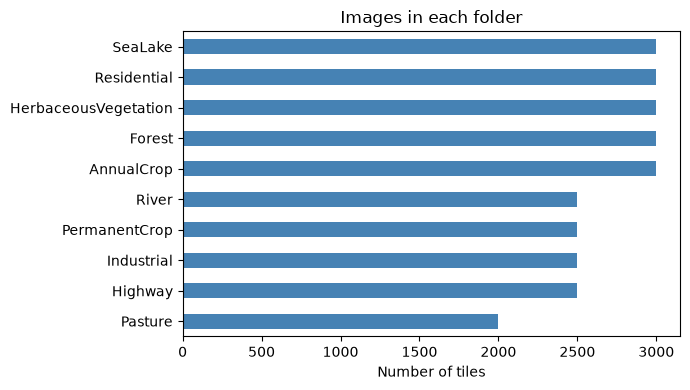

In [ ]:
counts = tiles["class"].value_counts().sort_values()

ax = counts.plot.barh(color="steelblue", figsize=(7, 4))

ax.set(xlabel="Number of tiles", ylabel="", title="Images in each folder")
plt.tight_layout()
plt.show()

- Pasture has 2,000 images, while the largest folders (SeaLake, Residential, HerbaceousVegetation, Forest and AnnualCrop) have 3,000 images each.
---

## Outliers within each class

- For each measurement, I check for outliers using the 1.5 × IQR rule.
- Values that are too far below the first quartile (Q1) or above the third quartile (Q3) are marked as outliers.
- I calculate these limits separately for each class, so darker forest images are compared with other forest images instead of images from different classes.

In [ ]:
by_class = tiles.groupby("class")

for name in ["brightness", "contrast"]:
    low = by_class[name].transform("quantile", q=0.25)
    high = by_class[name].transform("quantile", q=0.75)
    margin = 1.5 * (high - low)
    tiles[name + "_flag"] = (tiles[name] < low - margin) | (tiles[name] > high + margin)

summary = by_class.agg(images=("path", "size"), median_brightness=("brightness", "median"),
                       brightness_flags=("brightness_flag", "sum"), contrast_flags=("contrast_flag", "sum"))

summary["brightness_flag_pct"] = 100 * summary["brightness_flags"] / summary["images"]

display(summary.round(1))

,images,median_brightness,brightness_flags,contrast_flags,brightness_flag_pct
class,,,,,
AnnualCrop,3000,120.3,8,7,0.3
Forest,3000,57.3,79,100,2.6
HerbaceousVegetation,3000,93.4,35,158,1.2
Highway,2500,88.7,159,30,6.4
Industrial,2500,120.9,129,32,5.2
Pasture,2000,77.9,14,35,0.7
PermanentCrop,2500,115.2,3,24,0.1
Residential,3000,96.8,162,5,5.4
River,2500,80.0,57,51,2.3


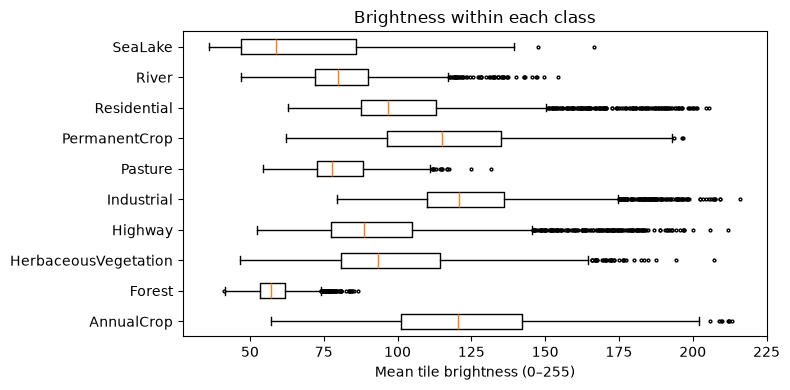

In [ ]:
classes = sorted(tiles["class"].unique())

fig, ax = plt.subplots(figsize=(8, 4))

ax.boxplot([group["brightness"] for _, group in by_class], tick_labels=classes,
           orientation="horizontal", flierprops={"markersize": 2})

ax.set(xlabel="Mean tile brightness (0–255)", title="Brightness within each class")

plt.tight_layout()
plt.show()

Each row below shows two dark tiles, one near the median, and two bright tiles. The number under each image is its brightness. This gives the boxplot points some context.

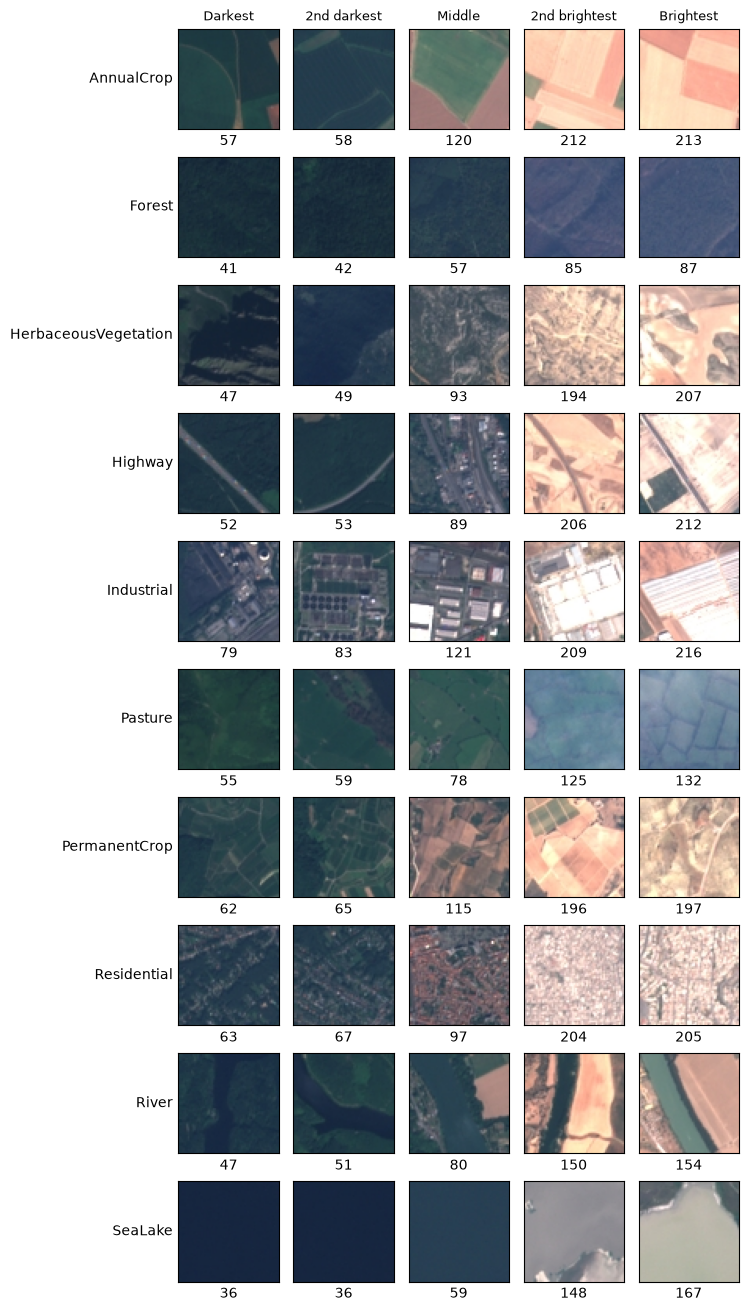

In [ ]:
fig, axes = plt.subplots(len(classes), 5, figsize=(7.4, 13), layout="constrained")

for row, (label, group) in enumerate(by_class):
    ordered = group.sort_values("brightness")
    examples = ordered.iloc[[0, 1, len(ordered) // 2, -2, -1]]

    for col, tile in enumerate(examples.itertuples()):
        ax = axes[row, col]

        with Image.open(tile.path) as img:
            ax.imshow(img)

        ax.set(xticks=[], yticks=[], xlabel=f"{tile.brightness:.0f}")

        if col == 0:
            ax.set_ylabel(label, rotation=0, ha="right", va="center")

for ax, title in zip(axes[0], ["Darkest", "2nd darkest", "Middle", "2nd brightest", "Brightest"]):
    ax.set_title(title, fontsize=9)

plt.show()

Residential has 162 brightness flags and SeaLake has two. That count depends on the spread inside each folder. 
- Brightness alone gives me too little evidence to remove any of these images.
---


## Do tiles in the same class look alike?

- I randomly selected 2,000 image pairs from each class using a fixed seed to make the results reproducible.
- I resized the images to 16 × 16 pixels and converted them to grayscale.
- Then I used Pearson correlation to check how similar the brightness patterns are between the images.
- If an image has the same brightness everywhere, the correlation cannot be calculated because there is no variation.

In [ ]:
rng = np.random.default_rng(42)
pair_frames = []

for label, group in by_class:
    left = rng.integers(len(group), size=2000)

    # A nonzero offset keeps a tile from being paired with itself.
    right = (left + rng.integers(1, len(group), size=2000)) % len(group)
    a_ids, b_ids = group.index.to_numpy()[left], group.index.to_numpy()[right]

    a = thumbnails[a_ids].astype(float)
    b = thumbnails[b_ids].astype(float)
    a -= a.mean(axis=1, keepdims=True)
    b -= b.mean(axis=1, keepdims=True)

    scale = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)
    corr = np.full(len(a), np.nan)
    np.divide((a * b).sum(axis=1), scale, out=corr, where=scale > 0)
    pair_frames.append(pd.DataFrame({"class": label, "left": a_ids, "right": b_ids, "r": corr}))

pairs = pd.concat(pair_frames, ignore_index=True)
scores = pairs.groupby("class")["r"]

display(scores.agg(["count", "median"]).join(scores.quantile(0.95).rename("95th percentile")).round(3))

,count,median,95th percentile
class,,,
AnnualCrop,2000,-0.004,0.389
Forest,2000,0.004,0.232
HerbaceousVegetation,2000,0.004,0.313
Highway,2000,0.005,0.284
Industrial,2000,0.046,0.285
Pasture,2000,-0.005,0.280
PermanentCrop,2000,-0.004,0.234
Residential,2000,-0.003,0.174
River,2000,0.006,0.318


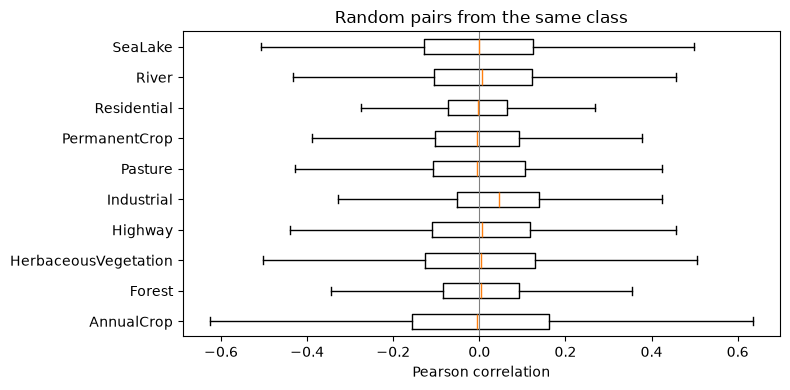

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.boxplot([g["r"].dropna() for _, g in pairs.groupby("class")],
           tick_labels=classes, orientation="horizontal", showfliers=False)

ax.axvline(0, color="gray", linewidth=0.8)
ax.set(xlabel="Pearson correlation", title="Random pairs from the same class")

plt.tight_layout()
plt.show()

- All ten medians are close to zero.
- For example, two river tiles might show similar landscapes but have the water in different positions.
- In this case, a low correlation makes sense because the images have different layouts.
- So, I would use the class labels to describe what the images show and correlation to compare how things are arranged in them.

## Similar-looking pairs

I also looked for matching 64-bit patterns across all folders. This is a quick way to find candidates for visual review. Flat water tiles can share a pattern, and shifting or rotating an image can change its pattern. The exact pixel hash above answers the narrower question of whether every RGB value matches.

Shared patterns: 40
Tiles in the largest group: 193
Patterns shared across labels: 1


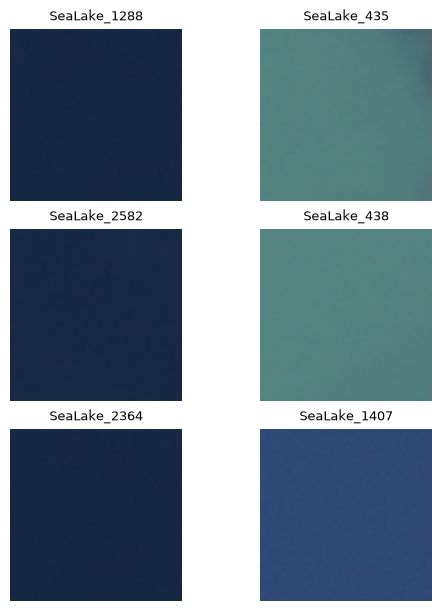

In [ ]:
matches = tiles[tiles["pattern"].duplicated(keep=False)]
groups = matches.groupby("pattern")
sizes = groups.size().sort_values(ascending=False)

print("Shared patterns:", len(sizes))
print("Tiles in the largest group:", sizes.max() if len(sizes) else 0)
print("Patterns shared across labels:", (groups["class"].nunique() > 1).sum())

if len(sizes):
    selected = sizes.head(3).index
    fig, axes = plt.subplots(len(selected), 2, figsize=(5, 2 * len(selected)), squeeze=False, layout="constrained")
    
    for axis_row, pattern in zip(axes, selected):
        group = groups.get_group(pattern).sort_values("brightness")
    
        for ax, tile in zip(axis_row, group.iloc[[0, -1]].itertuples()):
    
            with Image.open(tile.path) as img:
                ax.imshow(img)
    
            ax.set_title(tile.path.stem, fontsize=9)
            ax.axis("off")
    
    plt.show()

The pixel check found zero exact copies. The small pattern hash produced 40 groups, with 193 tiles in the largest one. A matching pattern would be a poor reason to delete that many tiles. I kept the valid images for the preprocessing notebook.